# NLP Text Classification with Detailed Text Preprocessing
**Artificial Intelligence and Smart System Research Lab – University Assignment**

---
## Section 1: Introduction

**What is NLP?**
Natural Language Processing (NLP) is the field of AI that lets computers read, process and understand human language.

**What is text classification?**
Text classification assigns a predefined label (class) to a piece of text, for example *spam / not spam* or *positive / negative*.

**Selected problem – Movie review sentiment classification.**
Given the text of a movie review, predict whether the sentiment is **positive** or **negative**.

**Dataset.** The *IMDB Movie Reviews* dataset (50,000 reviews, a `review` text column and a `sentiment` label column), downloaded from an online GitHub repository and stored in `data/IMDB_Dataset.csv`. Raw web text is a good fit for a preprocessing assignment because it contains HTML tags, mixed case, punctuation, URLs and negations.

**Objective.** Show **step by step** how raw text is transformed into clean text, how clean text becomes numerical features, and how those features are used for basic classification.

**Workflow**

`Raw text → Preprocessing (10 steps) → Feature extraction (BoW / TF-IDF / n-grams) → Classifiers (LR, SVM, NB) → Evaluation → Prediction`

---
## Section 2: Library Installation and Import

Only the libraries that are needed are used. If any are missing in your Conda environment, uncomment and run the install cell below once.

In [4]:
# Run once if a library is missing (remove the leading '#').
# %pip install pandas numpy matplotlib seaborn nltk scikit-learn

In [5]:
import os
import re
import json
import random
import textwrap
import warnings
import urllib.request
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Relative paths (run the notebook from the project folder)
DATA_PATH = os.path.join("data", "IMDB_Dataset.csv")
FIG_DIR = os.path.join("outputs", "figures")
RES_DIR = os.path.join("outputs", "results")
os.makedirs("data", exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
print("Libraries imported. Random seed =", SEED)

Libraries imported. Random seed = 42


In [ ]:
# Download the NLTK resources used in this notebook (only downloads if missing).
for resource in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=Tru2e)
print("NLTK resources ready.")

NLTK resources ready.


---
## Section 3: Dataset Exploration

### 3.1 Load the dataset
The CSV file is loaded with `pandas`. The original file is **never modified**; all later changes are made on copies. If the file is missing, it is downloaded from the public GitHub source.

In [7]:
DATA_URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"

if not os.path.exists(DATA_PATH):
    print("Dataset not found locally - downloading from:", DATA_URL)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Dataset loaded from:", DATA_PATH)

Dataset loaded from: data\IMDB_Dataset.csv


### 3.2 First five records
`head()` gives a quick look at what the data looks like.

In [8]:
display(df.head())

,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as ...",positive
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and g...,positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fightin...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portr...",positive


### 3.3 Dimensions, column names and data types
We check how many records there are and which columns hold the **text** and the **label**.

In [9]:
print("Shape (rows, columns):", df.shape)
print()
print("Column names:", list(df.columns))
print()
print(df.dtypes)

# Identified from the inspection above
TEXT_COL = "review"      # the raw movie review text
LABEL_COL = "sentiment"  # the target class (positive / negative)
print(f"\nText column  : '{TEXT_COL}'\nLabel column : '{LABEL_COL}'")

Shape (rows, columns): (50000, 2)

Column names: ['review', 'sentiment']

review       object
sentiment    object
dtype: object

Text column  : 'review'
Label column : 'sentiment'


### 3.4 Missing values
Missing text cannot be processed, so we count missing values per column.

In [10]:
print(df.isnull().sum())
print("\nTotal missing values:", int(df.isnull().sum().sum()))

review       0
sentiment    0
dtype: int64

Total missing values: 0


### 3.5 Duplicate records
Identical reviews that appear in both the training and test sets would inflate the results, so we check for duplicates (they are removed from the *working copy* in Section 3.9).

In [11]:
n_duplicates = int(df.duplicated().sum())
print("Number of duplicate rows:", n_duplicates)

Number of duplicate rows: 418


### 3.6 Class distribution
A balanced dataset makes accuracy a fair metric.

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


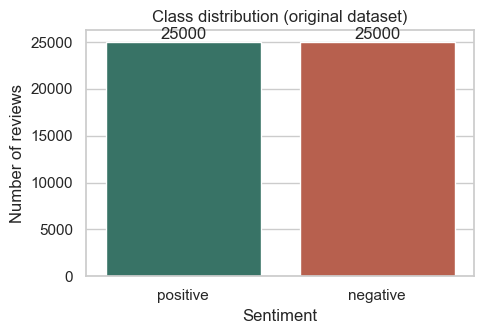

In [12]:
class_counts = df[LABEL_COL].value_counts()
print(class_counts)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=LABEL_COL, order=class_counts.index, palette=["#2E7D6B", "#C8553D"], ax=ax)
ax.set_title("Class distribution (original dataset)")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of reviews")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

### 3.7 Text length analysis
The number of words per review tells us how long the documents are.

count    50000.0
mean       231.2
std        171.3
min          4.0
25%        126.0
50%        173.0
75%        280.0
max       2470.0
Name: review, dtype: float64


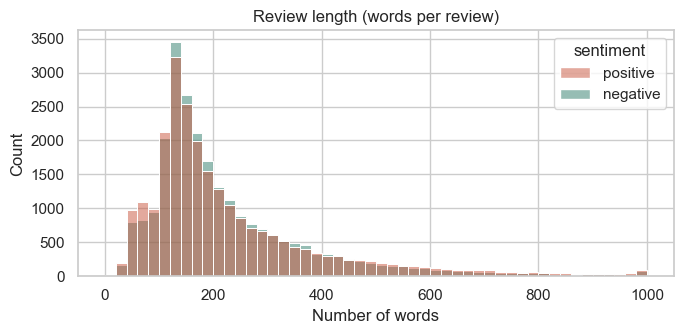

In [13]:
word_counts = df[TEXT_COL].str.split().str.len()
print(word_counts.describe().round(1))

length_df = pd.DataFrame({"words": word_counts, "sentiment": df[LABEL_COL]})
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=length_df, x="words", hue="sentiment", bins=50, binrange=(0, 1000),
             palette=["#C8553D", "#2E7D6B"], ax=ax)
ax.set_title("Review length (words per review)")
ax.set_xlabel("Number of words")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "text_length.png"), dpi=150, bbox_inches="tight")
plt.show()

### 3.8 A few original text samples
Notice the raw noise: HTML tags (`<br />`), mixed case, punctuation and contractions. (Samples are shortened to 300 characters for display.)

In [14]:
for _, row in df.sample(3, random_state=SEED).iterrows():
    print(f"[{row[LABEL_COL].upper()}]", textwrap.shorten(row[TEXT_COL], width=300, placeholder=" ..."))
    print()

[POSITIVE] I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ...

[POSITIVE] Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as you can think of that just adore this T.V miniseries. It has elements that can be found in almost ...

[NEGATIVE] The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but that probably would have ended the whole premise for the movie.<br /><br />It seems like they ...



### 3.9 Create the working dataset
To keep the notebook fast on a normal laptop, a **stratified random sample of 10,000 reviews** is used (set `SAMPLE_SIZE = None` to use all reviews). Duplicates are dropped from this working copy first. The original `df` and the CSV file stay unchanged.

In [15]:
SAMPLE_SIZE = 10000   # set to None to use the full dataset (slower)

df_work = df.dropna(subset=[TEXT_COL, LABEL_COL]).drop_duplicates().reset_index(drop=True)
n_after_dedup = len(df_work)

if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df_work):
    df_work, _ = train_test_split(df_work, train_size=SAMPLE_SIZE,
                                  stratify=df_work[LABEL_COL], random_state=SEED)
    df_work = df_work.reset_index(drop=True)

print("Original rows          :", len(df))
print("After removing duplicates:", n_after_dedup)
print("Working dataset rows   :", len(df_work))
print()
print(df_work[LABEL_COL].value_counts())

Original rows          : 50000
After removing duplicates: 49582
Working dataset rows   : 10000

sentiment
positive    5019
negative    4981
Name: count, dtype: int64


---
## Section 4: Detailed Text Preprocessing

Raw text is messy. Machine-learning models need *consistent* input, so we clean the text in ten ordered steps.
Every step is shown **separately** on the **same sample review**: what it does, why it is needed, the code, the original text and the output.

### Sample review used in every step
We pick one real review from the dataset that contains HTML tags, capital letters and negations (such as *don't*, *not*).

In [16]:
candidates = df_work[
    df_work[TEXT_COL].str.contains("<br />")
    & df_work[TEXT_COL].str.split().str.len().between(35, 55)
    & df_work[TEXT_COL].str.contains("n't")
    & df_work[TEXT_COL].str.contains(r"[A-Z]")
]
sample_text = candidates.sample(1, random_state=SEED)[TEXT_COL].iloc[0]

def show(label, before, after):
    # Helper that prints the text before and after a step (wrapped for readability).
    print("BEFORE:")
    print(textwrap.fill(str(before), 110))
    print(f"\nAFTER ({label}):")
    print(textwrap.fill(str(after), 110))

print("ORIGINAL SAMPLE REVIEW:")
print(textwrap.fill(sample_text, 110))

ORIGINAL SAMPLE REVIEW:
While this is a faithful adaptation, it is much less exciting than Greene's novel. Also, it's a bit ridiculous
when people say things to Boyer like, "You're Spanish, aren't you?"<br /><br />Still, the movie's not at all
bad, just slow-moving.<br /><br />


### Step 1: Lowercasing
**What it does:** converts every character to lowercase.

**Why it is required (text normalization):** a computer treats `Movie`, `MOVIE` and `movie` as three different words. Lowercasing maps them to one form, which shrinks the vocabulary and makes counting more reliable.

In [17]:
step1_lower = sample_text.lower()
show("lowercase", sample_text, step1_lower)

BEFORE:
While this is a faithful adaptation, it is much less exciting than Greene's novel. Also, it's a bit ridiculous
when people say things to Boyer like, "You're Spanish, aren't you?"<br /><br />Still, the movie's not at all
bad, just slow-moving.<br /><br />

AFTER (lowercase):
while this is a faithful adaptation, it is much less exciting than greene's novel. also, it's a bit ridiculous
when people say things to boyer like, "you're spanish, aren't you?"<br /><br />still, the movie's not at all
bad, just slow-moving.<br /><br />


### Step 2: HTML Tag Removal
**What it does:** removes HTML markup such as `<br />` or `<p>` using a regular expression.

**Why it is required:** reviews were copied from web pages, so tags like `<br />` are layout code, not language. They carry no sentiment and would become meaningless tokens (`br`).

**Regex used:** `</?[a-z][^>]*>` matches an opening or closing tag. We replace it with a space so that neighbouring words do not stick together.

In [18]:
step2_no_html = re.sub(r"</?[a-z][^>]*>", " ", step1_lower)
show("HTML removed", step1_lower, step2_no_html)

BEFORE:
while this is a faithful adaptation, it is much less exciting than greene's novel. also, it's a bit ridiculous
when people say things to boyer like, "you're spanish, aren't you?"<br /><br />still, the movie's not at all
bad, just slow-moving.<br /><br />

AFTER (HTML removed):
while this is a faithful adaptation, it is much less exciting than greene's novel. also, it's a bit ridiculous
when people say things to boyer like, "you're spanish, aren't you?"  still, the movie's not at all bad, just
slow-moving.


### Step 3: URL Removal
**What it does:** removes web addresses (`http://...`, `https://...`, `www....`) using a regular expression.

**Why it is required:** a URL is almost always unique, so it adds a useless feature that never helps to predict the class.

Our sample review has no URL, so below we first apply the step to it (no change expected) and then to **a real review from the dataset that does contain a URL**.

In [19]:
URL_PATTERN = r"(https?://\S+|www\.\S+)"

step3_no_url = re.sub(URL_PATTERN, " ", step2_no_html)
print("Sample review changed by this step?", step3_no_url != step2_no_html)

# Demonstration on a real review that contains a URL (excerpt around the URL)
url_review = df[df[TEXT_COL].str.contains(URL_PATTERN)].iloc[0][TEXT_COL]
match = re.search(URL_PATTERN, url_review)
excerpt = url_review[max(0, match.start() - 60): match.end() + 30]
print()
show("URL removed", excerpt, re.sub(URL_PATTERN, " ", excerpt))

Sample review changed by this step? False

BEFORE:
EPTIC'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :www.cei.org. A shorter 10-page version can

AFTER (URL removed):
EPTIC'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :  A shorter 10-page version can


### Step 4: Special Character and Punctuation Removal
**What it does:** removes punctuation, digits and symbols so that only letters and spaces remain.

**Why it is required:** characters such as `!`, `"`, `(`, `/` do not help a bag-of-words model and would create separate tokens like `bad.` and `bad`.

**Care for negations:** removing the apostrophe turns `didn't` into `didn t`, which would lose the word *not*. So we first expand the common negative contractions (`n't` → ` not`), then remove everything that is not a letter.

In [20]:
def expand_negations(text):
    # won't / can't are irregular, the rest end with n't
    text = text.replace("won't", "will not").replace("can't", "can not")
    return text.replace("n't", " not")

step4_expanded = expand_negations(step3_no_url)
step4_clean = re.sub(r"[^a-z\s]", " ", step4_expanded)   # keep only letters and whitespace
show("special characters removed", step3_no_url, step4_clean)

BEFORE:
while this is a faithful adaptation, it is much less exciting than greene's novel. also, it's a bit ridiculous
when people say things to boyer like, "you're spanish, aren't you?"  still, the movie's not at all bad, just
slow-moving.

AFTER (special characters removed):
while this is a faithful adaptation  it is much less exciting than greene s novel  also  it s a bit ridiculous
when people say things to boyer like   you re spanish  are not you    still  the movie s not at all bad  just
slow moving


### Step 5: Whitespace Normalization
**What it does:** replaces any run of spaces, tabs and newline characters with a single space and trims the ends.

**Why it is required:** the previous steps left many extra spaces where tags and symbols used to be. Clean spacing keeps the text tidy and tokenization predictable.

In [21]:
step5_spaces = re.sub(r"\s+", " ", step4_clean).strip()
show("whitespace normalized", step4_clean, step5_spaces)
print("\nCharacters before:", len(step4_clean), "| after:", len(step5_spaces))

BEFORE:
while this is a faithful adaptation  it is much less exciting than greene s novel  also  it s a bit ridiculous
when people say things to boyer like   you re spanish  are not you    still  the movie s not at all bad  just
slow moving

AFTER (whitespace normalized):
while this is a faithful adaptation it is much less exciting than greene s novel also it s a bit ridiculous
when people say things to boyer like you re spanish are not you still the movie s not at all bad just slow
moving

Characters before: 235 | after: 221


### Step 6: Tokenization
**What it does:** splits the cleaned text into individual words called **tokens**.

**Why it is required:** later steps (stopword removal, stemming, lemmatization) work on single words, so the text must become a *list of words*. We use `nltk.tokenize.word_tokenize`.

In [22]:
step6_tokens = word_tokenize(step5_spaces)
print("Cleaned text :", step5_spaces[:100], "...")
print("\nTokens       :", step6_tokens)
print("\nNumber of tokens:", len(step6_tokens))

Cleaned text : while this is a faithful adaptation it is much less exciting than greene s novel also it s a bit rid ...

Tokens       : ['while', 'this', 'is', 'a', 'faithful', 'adaptation', 'it', 'is', 'much', 'less', 'exciting', 'than', 'greene', 's', 'novel', 'also', 'it', 's', 'a', 'bit', 'ridiculous', 'when', 'people', 'say', 'things', 'to', 'boyer', 'like', 'you', 're', 'spanish', 'are', 'not', 'you', 'still', 'the', 'movie', 's', 'not', 'at', 'all', 'bad', 'just', 'slow', 'moving']

Number of tokens: 45


### Step 7: Stopword Removal
**What are stopwords?** Very frequent words such as *the, is, and, of, a, to* that carry little meaning on their own.

**Why remove them:** they appear in every review, so they do not help to tell positive from negative, and removing them makes the data smaller.

**Important – keep negations.** The NLTK list contains `no`, `nor` and `not`. Dropping them would turn *"not good"* into *"good"* and flip the sentiment, so we **remove them from the stopword list** (and also keep `never`). Single-letter leftovers (e.g. `s`, `t` from `it's`) are dropped too.

In [23]:
negation_words = {"no", "nor", "not", "never"}
stop_words = set(stopwords.words("english")) - negation_words

print("NLTK English stopwords :", len(stopwords.words("english")))
print("Negations we keep      :", sorted(negation_words))
print("Stopword list we use   :", len(stop_words))

step7_no_stop = [t for t in step6_tokens if t not in stop_words and len(t) > 1]
removed = [t for t in step6_tokens if t in stop_words or len(t) <= 1]

print("\nTokens BEFORE:", step6_tokens)
print("\nTokens AFTER :", step7_no_stop)
print("\nRemoved words:", removed)
print("Negations kept:", [t for t in step7_no_stop if t in negation_words])

NLTK English stopwords : 198
Negations we keep      : ['never', 'no', 'nor', 'not']
Stopword list we use   : 195

Tokens BEFORE: ['while', 'this', 'is', 'a', 'faithful', 'adaptation', 'it', 'is', 'much', 'less', 'exciting', 'than', 'greene', 's', 'novel', 'also', 'it', 's', 'a', 'bit', 'ridiculous', 'when', 'people', 'say', 'things', 'to', 'boyer', 'like', 'you', 're', 'spanish', 'are', 'not', 'you', 'still', 'the', 'movie', 's', 'not', 'at', 'all', 'bad', 'just', 'slow', 'moving']

Tokens AFTER : ['faithful', 'adaptation', 'much', 'less', 'exciting', 'greene', 'novel', 'also', 'bit', 'ridiculous', 'people', 'say', 'things', 'boyer', 'like', 'spanish', 'not', 'still', 'movie', 'not', 'bad', 'slow', 'moving']

Removed words: ['while', 'this', 'is', 'a', 'it', 'is', 'than', 's', 'it', 's', 'a', 'when', 'to', 'you', 're', 'are', 'you', 'the', 's', 'at', 'all', 'just']
Negations kept: ['not', 'not']


### Step 8: Stemming (Porter Stemmer)
**What it does:** cuts each word down to a *stem* by chopping common endings using fixed rules (`running → run`, `movies → movi`).

**Why it is required:** `watch`, `watching` and `watched` express the same idea. Stemming maps them to one feature, so the vocabulary shrinks.

**Advantages:** very fast and simple; reduces vocabulary size.
**Limitations:** the stem is often **not a real word** (`movi`, `studi`), and the rules can be wrong (over-stemming).

In [24]:
stemmer = PorterStemmer()
step8_stemmed = [stemmer.stem(t) for t in step7_no_stop]

stem_table = pd.DataFrame({"before (token)": step7_no_stop, "after (stem)": step8_stemmed})
changed = stem_table[stem_table["before (token)"] != stem_table["after (stem)"]]
print(f"{len(changed)} of {len(stem_table)} tokens were changed by stemming. Examples:")
display(changed.head(12).reset_index(drop=True))
print("Stemmed tokens:", step8_stemmed)

9 of 23 tokens were changed by stemming. Examples:


,before (token),after (stem)
0,faithful,faith
1,adaptation,adapt
2,exciting,excit
3,greene,green
4,ridiculous,ridicul
5,people,peopl
6,things,thing
7,movie,movi
8,moving,move


Stemmed tokens: ['faith', 'adapt', 'much', 'less', 'excit', 'green', 'novel', 'also', 'bit', 'ridicul', 'peopl', 'say', 'thing', 'boyer', 'like', 'spanish', 'not', 'still', 'movi', 'not', 'bad', 'slow', 'move']


### Step 9: Lemmatization (WordNet Lemmatizer)
**What it does:** converts each word to its dictionary form, the **lemma**, by looking it up in WordNet (`movies → movie`, `feet → foot`).

**Stemming vs lemmatization**

| | Stemming | Lemmatization |
|---|---|---|
| Method | chops endings with rules | dictionary lookup (WordNet) |
| Output | may be a non-word (`movi`) | always a real word (`movie`) |
| Speed | faster | slightly slower |
| Accuracy | lower | higher |

By default the lemmatizer treats every word as a noun; passing `pos="v"` handles verbs (see the small illustration below).

In [25]:
lemmatizer = WordNetLemmatizer()
step9_lemmas = [lemmatizer.lemmatize(t) for t in step7_no_stop]

lemma_table = pd.DataFrame({"before (token)": step7_no_stop,
                            "stem": step8_stemmed,
                            "lemma": step9_lemmas})
changed = lemma_table[lemma_table["before (token)"] != lemma_table["lemma"]]
print(f"{len(changed)} of {len(lemma_table)} tokens were changed by lemmatization. Examples:")
display(changed.head(12).reset_index(drop=True))
print("Lemmatized tokens:", step9_lemmas)

1 of 23 tokens were changed by lemmatization. Examples:


,before (token),stem,lemma
0,things,thing,thing


Lemmatized tokens: ['faithful', 'adaptation', 'much', 'less', 'exciting', 'greene', 'novel', 'also', 'bit', 'ridiculous', 'people', 'say', 'thing', 'boyer', 'like', 'spanish', 'not', 'still', 'movie', 'not', 'bad', 'slow', 'moving']


In [26]:
# Small illustration (hand-picked words, not from the dataset) of stem vs lemma
demo_words = ["studies", "movies", "better", "feet", "running"]
print(pd.DataFrame({
    "word": demo_words,
    "stem": [stemmer.stem(w) for w in demo_words],
    "lemma (noun, default)": [lemmatizer.lemmatize(w) for w in demo_words],
    "lemma (pos='v')": [lemmatizer.lemmatize(w, pos="v") for w in demo_words],
}).to_string(index=False))

   word   stem lemma (noun, default) lemma (pos='v')
studies  studi                 study           study
 movies   movi                 movie          movies
 better better                better          better
   feet   feet                  foot            feet
running    run               running             run


### Step 10: Final Processed Text
**What it does:** joins the final tokens back into one string.

**Why it is required:** scikit-learn vectorizers (Section 6) expect each document as a single string of words. We use the **lemmatized** tokens as our final text because lemmas are real words and easier to interpret.

In [27]:
step10_final = " ".join(step9_lemmas)

print("ORIGINAL TEXT:")
print(textwrap.fill(sample_text, 110))
print("\nFINAL PROCESSED TEXT:")
print(textwrap.fill(step10_final, 110))

ORIGINAL TEXT:
While this is a faithful adaptation, it is much less exciting than Greene's novel. Also, it's a bit ridiculous
when people say things to Boyer like, "You're Spanish, aren't you?"<br /><br />Still, the movie's not at all
bad, just slow-moving.<br /><br />

FINAL PROCESSED TEXT:
faithful adaptation much less exciting greene novel also bit ridiculous people say thing boyer like spanish
not still movie not bad slow moving


### 4.12 Apply the pipeline to the whole working dataset
We store the intermediate token lists too, because Section 5 compares them.

In [29]:
df_work["tokens"] = df_work[TEXT_COL].apply(lambda t: tokenize(clean_text(t)))
df_work["tokens_no_stop"] = df_work["tokens"].apply(remove_stopwords)
df_work["tokens_stemmed"] = df_work["tokens_no_stop"].apply(stem_tokens)
df_work["tokens_lemma"] = df_work["tokens_no_stop"].apply(lemmatize_tokens)
df_work["clean_text"] = df_work["tokens_lemma"].apply(" ".join)

# Reviews that became empty after cleaning cannot be used
n_empty = int((df_work["clean_text"].str.len() == 0).sum())
df_work = df_work[df_work["clean_text"].str.len() > 0].reset_index(drop=True)
print("Empty texts removed:", n_empty, "| Rows kept:", len(df_work))

display(df_work[[TEXT_COL, "clean_text"]].head(3).assign(
    **{TEXT_COL: lambda d: d[TEXT_COL].str.slice(0, 200) + " ..."}))

Empty texts removed: 0 | Rows kept: 10000


,review,clean_text
0,I only wish that I had the good sense to turn this movie off in the beginning when I knew it was terrible. <br /><br...,wish good sense turn movie beginning knew terrible instead gave benefit doubt waited get better not make mistake tit...
1,"CAT SOUP is a short anime based on the legendary manga Nekojiru. It won the award ""Best Short Film"" at The 6th Fanta...",cat soup short anime based legendary manga nekojiru award best short film th fantasia film festival also excellence ...
2,How any of you gave this more than 2 stars amazes me. I made an account on IMDb just to comment on this cr@p film. T...,gave star amazes made account imdb comment cr film acting cr plot cr would deserve no star not descent soundtrack ye...


---
## Section 5: Preprocessing Comparison

Five real, short reviews from the dataset, shown after each stage. (*Tokenized* = after steps 1-6; *Stopword Removed* = step 7; *Stemmed* = step 8; *Lemmatized* = step 9.)

In [30]:
short_reviews = df_work[df_work[TEXT_COL].str.split().str.len().between(12, 25)]
samples = short_reviews.sample(5, random_state=SEED)

rows = []
for text in samples[TEXT_COL]:
    tokens = tokenize(clean_text(text))
    no_stop = remove_stopwords(tokens)
    rows.append({
        "Original Text": text,
        "Lowercase": to_lowercase(text),
        "Tokenized": " ".join(tokens),
        "Stopword Removed": " ".join(no_stop),
        "Stemmed": " ".join(stem_tokens(no_stop)),
        "Lemmatized": " ".join(lemmatize_tokens(no_stop)),
    })
comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(os.path.join(RES_DIR, "preprocessing_comparison.csv"), index=False)

with pd.option_context("display.max_colwidth", None):
    display(comparison_df)

,Original Text,Lowercase,Tokenized,Stopword Removed,Stemmed,Lemmatized
0,"Brilliant. Ranks along with Citizen Kane, The Matrix and Godfathers. Must see, at least for basset in her early days. Watch it.","brilliant. ranks along with citizen kane, the matrix and godfathers. must see, at least for basset in her early days. watch it.",brilliant ranks along with citizen kane the matrix and godfathers must see at least for basset in her early days watch it,brilliant ranks along citizen kane matrix godfathers must see least basset early days watch,brilliant rank along citizen kane matrix godfath must see least basset earli day watch,brilliant rank along citizen kane matrix godfather must see least basset early day watch
1,a mesmerizing film that certainly keeps your attention... Ben Daniels is fascinating (and courageous) to watch.,a mesmerizing film that certainly keeps your attention... ben daniels is fascinating (and courageous) to watch.,a mesmerizing film that certainly keeps your attention ben daniels is fascinating and courageous to watch,mesmerizing film certainly keeps attention ben daniels fascinating courageous watch,mesmer film certainli keep attent ben daniel fascin courag watch,mesmerizing film certainly keep attention ben daniel fascinating courageous watch
2,This is quite possibly the worst sequel ever made. The script is unfunny and the acting stinks. The exact opposite of the original.,this is quite possibly the worst sequel ever made. the script is unfunny and the acting stinks. the exact opposite of the original.,this is quite possibly the worst sequel ever made the script is unfunny and the acting stinks the exact opposite of the original,quite possibly worst sequel ever made script unfunny acting stinks exact opposite original,quit possibl worst sequel ever made script unfunni act stink exact opposit origin,quite possibly worst sequel ever made script unfunny acting stink exact opposite original
3,"This is a terrible movie, don't waste your money on it. Don't even watch it for free. That's all I have to say.","this is a terrible movie, don't waste your money on it. don't even watch it for free. that's all i have to say.",this is a terrible movie do not waste your money on it do not even watch it for free that s all i have to say,terrible movie not waste money not even watch free say,terribl movi not wast money not even watch free say,terrible movie not waste money not even watch free say
4,"Great story, great music. A heartwarming love story that's beautiful to watch and delightful to listen to. Too bad there is no soundtrack CD.","great story, great music. a heartwarming love story that's beautiful to watch and delightful to listen to. too bad there is no soundtrack cd.",great story great music a heartwarming love story that s beautiful to watch and delightful to listen to too bad there is no soundtrack cd,great story great music heartwarming love story beautiful watch delightful listen bad no soundtrack cd,great stori great music heartwarm love stori beauti watch delight listen bad no soundtrack cd,great story great music heartwarming love story beautiful watch delightful listen bad no soundtrack cd


**Stemming vs lemmatization – what to notice in the table**

- **Stemming** cuts word endings with rules, so you will often see **non-words** (for example `movi`, `stori`, `veri`). It is fast but crude.
- **Lemmatization** uses a dictionary and returns **real words** (`movie`, `story`), so the text stays readable.
- Both reduce different forms of a word to a common form, which makes the vocabulary smaller.

The next table measures this on the whole working dataset.

In [ ]:
def vocab_size(token_lists):
    return len(set(t for tokens in token_lists for t in tokens))

stage_stats = pd.DataFrame({
    "Stage": ["After tokenization", "After stopword removal", "After stemming", "After lemmatization"],
    "Avg tokens per review": [df_work["tokens"].str.len().mean(),
                              df_work["tokens_no_stop"].str.len().mean(),
                              df_work["tokens_stemmed"].str.len().mean(),
                              df_work["tokens_lemma"].str.len().mean()],
    "Vocabulary size (unique words)": [vocab_size(df_work["tokens"]),
                                       vocab_size(df_work["tokens_no_stop"]),
                                       vocab_size(df_work["tokens_stemmed"]),
                                       vocab_size(df_work["tokens_lemma"])],
}).round(1)
stage_stats.to_csv(os.path.join(RES_DIR, "preprocessing_stage_statistics.csv"), index=False)
display(sta ge_stats)

,Stage,Avg tokens per review,Vocabulary size (unique words)
0,After tokenization,233.6,51135
1,After stopword removal,120.8,50976
2,After stemming,120.8,34597
3,After lemmatization,120.8,45576


---
## Section 6: Feature Extraction

Machine-learning models need **numbers**, not words. Feature extraction converts each cleaned review into a numeric vector.

### 6.1 Train-test split (80:20, stratified)
The split is done **before** fitting any vectorizer. The vectorizers learn their vocabulary **only from the training data**; the test data is only *transformed*. This prevents **data leakage**.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    df_work["clean_text"], df_work[LABEL_COL],
    test_size=0.20, stratify=df_work[LABEL_COL], random_state=SEED)

print("Training samples:", len(X_train), "| Test samples:", len(X_test))
print("\nTraining class distribution:\n", y_train.value_counts())
print("\nTest class distribution:\n", y_test.value_counts())

Training samples: 8000 | Test samples: 2000

Training class distribution:
 sentiment
positive    4015
negative    3985
Name: count, dtype: int64

Test class distribution:
 sentiment
positive    1004
negative     996
Name: count, dtype: int64


### 6.2 Bag of Words (CountVectorizer)
**Idea:** build a **vocabulary** of all words and represent each document by **how many times** each word occurs. Word order is ignored (a "bag" of words). Each column is a word (feature) and each row is a document.

First, a tiny illustration with three real short training reviews:

In [33]:
doc_lengths = X_train.str.split().str.len()
long_enough = X_train[doc_lengths >= 6]                      # skip near-empty reviews
tiny_docs = long_enough.iloc[doc_lengths[long_enough.index].values.argsort()[:3]].tolist()  # 3 shortest
tiny_vec = CountVectorizer()
tiny_matrix = tiny_vec.fit_transform(tiny_docs)
tiny_bow = pd.DataFrame(tiny_matrix.toarray(), columns=tiny_vec.get_feature_names_out(),
                        index=[f"doc {i+1}" for i in range(len(tiny_docs))])
for i, d in enumerate(tiny_docs, 1):
    print(f"doc {i}: {d}")
display(tiny_bow)

doc 1: add little gem list holiday regular sweet funny endearing
doc 2: not seen terrible pure trash saw year ago still screwed
doc 3: mesmerizing film certainly keep attention ben daniel fascinating courageous watch


,add,ago,attention,ben,certainly,courageous,daniel,endearing,fascinating,film,...,regular,saw,screwed,seen,still,sweet,terrible,trash,watch,year
doc 1,1,0,0,0,0,0,0,1,0,0,...,1,0,0,0,0,1,0,0,0,0
doc 2,0,1,0,0,0,0,0,0,0,0,...,0,1,1,1,1,0,1,1,0,1
doc 3,0,0,1,1,1,1,1,0,1,1,...,0,0,0,0,0,0,0,0,1,0


Now Bag of Words on the full **training** set (limited to the 5,000 most frequent words):

In [34]:
bow_vectorizer = CountVectorizer(max_features=5000)
X_train_bow = bow_vectorizer.fit_transform(X_train)   # learn vocabulary from TRAIN only
X_test_bow = bow_vectorizer.transform(X_test)         # TEST is only transformed

print("Vocabulary size      :", len(bow_vectorizer.vocabulary_))
print("Train matrix shape   :", X_train_bow.shape, "(documents x words)")
print("Test matrix shape    :", X_test_bow.shape)
sparsity = 100 * (1 - X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1]))
print(f"Sparsity (zeros)     : {sparsity:.1f}%")

top_words = pd.Series(np.asarray(X_train_bow.sum(axis=0)).ravel(),
                      index=bow_vectorizer.get_feature_names_out()).sort_values(ascending=False).head(10)
print("\nTen most frequent words in training data:")
print(top_words.to_string())

Vocabulary size      : 5000
Train matrix shape   : (8000, 5000) (documents x words)
Test matrix shape    : (2000, 5000)
Sparsity (zeros)     : 98.4%

Ten most frequent words in training data:
not          20599
movie        16664
film         14907
one           8919
like          6714
time          5039
good          4765
character     4510
would         4260
get           4103


### 6.3 TF-IDF (TfidfVectorizer)
Raw counts favour words that are simply frequent (like *movie* or *film*). **TF-IDF** rewards words that are important for one document but not common everywhere.

- **Term Frequency (TF):** how often a word appears in a document.
- **Inverse Document Frequency (IDF):** how *rare* a word is across all documents (`IDF = log(N / df)`, smoothed in scikit-learn). Common words get a low IDF, rare words a high IDF.
- **TF-IDF = TF × IDF**, then each document vector is normalized.

This is the **main feature representation** used for the classifiers. It uses unigrams **and** bigrams (see 6.4), at least 2 documents per term, and at most 20,000 features.

In [35]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000)
X_train_tfidf = tfidf.fit_transform(X_train)   # fit on TRAIN only
X_test_tfidf = tfidf.transform(X_test)         # transform TEST

print("TF-IDF train matrix shape:", X_train_tfidf.shape)
print("TF-IDF test matrix shape :", X_test_tfidf.shape)

feature_names = np.array(tfidf.get_feature_names_out())

# Sample feature values: the 10 highest-weighted terms of the first training review
row = X_train_tfidf[0].toarray().ravel()
top_idx = row.argsort()[::-1][:10]
print("\nFirst training review (processed):", textwrap.shorten(X_train.iloc[0], 160, placeholder=" ..."))
display(pd.DataFrame({"term": feature_names[top_idx], "tf-idf value": row[top_idx].round(3)}))

# IDF: common words get low values, rare words get high values
idf = pd.Series(tfidf.idf_, index=feature_names).sort_values()
print("Lowest IDF (very common terms):")
print(idf.head(5).round(2).to_string())
print("\nHighest IDF (rare terms):")
print(idf.tail(5).round(2).to_string())

TF-IDF train matrix shape: (8000, 20000)
TF-IDF test matrix shape : (2000, 20000)

First training review (processed): way underrated gem lost nothing power year ago connects pretty wide variety different character story without appearing cluttered clothes music might ...


,term,tf-idf value
0,time end,0.194
1,connects,0.194
2,wide variety,0.194
3,earlier movie,0.191
4,story without,0.185
5,end story,0.185
6,story never,0.179
7,show really,0.179
8,miss one,0.178
9,different character,0.175


Lowest IDF (very common terms):
not      1.20
movie    1.43
film     1.53
one      1.54
like     1.74

Highest IDF (rare terms):
brodie              8.89
bluebeard eighth    8.89
whistler            8.89
bluebeard           8.89
bjarne              8.89


### 6.4 N-grams (unigrams and bigrams)
An **n-gram** is a sequence of *n* consecutive words.

- **Unigram (n = 1):** single words, e.g. `not`, `good`.
- **Bigram (n = 2):** pairs of neighbouring words, e.g. `not good`.

Bigrams capture **word combinations** that a bag of single words cannot: `not good` (negative) has the opposite meaning of `good` alone. This is another reason we kept the negation words in Step 7.

In [36]:
demo_clean = step10_final   # the processed sample review from Section 4

uni = CountVectorizer(ngram_range=(1, 1)).fit([demo_clean])
bi = CountVectorizer(ngram_range=(2, 2)).fit([demo_clean])

print("Processed sample:", textwrap.shorten(demo_clean, 150, placeholder=" ..."))
print("\nUnigrams:", list(uni.get_feature_names_out())[:12], "...")
print("\nBigrams :", list(bi.get_feature_names_out())[:12], "...")

# Most frequent bigrams in the training data
bigram_vec = CountVectorizer(ngram_range=(2, 2), min_df=5)
bigram_matrix = bigram_vec.fit_transform(X_train)
bigram_counts = pd.Series(np.asarray(bigram_matrix.sum(axis=0)).ravel(),
                          index=bigram_vec.get_feature_names_out()).sort_values(ascending=False)
print("\nTop 10 bigrams in the training data:")
print(bigram_counts.head(10).to_string())

print("\nSome frequent bigrams that contain a negation:")
neg_bigrams = bigram_counts[bigram_counts.index.str.contains(r"\b(?:not|no|never)\b")]
print(neg_bigrams.head(8).to_string())

Processed sample: faithful adaptation much less exciting greene novel also bit ridiculous people say thing boyer like spanish not still movie not bad slow moving

Unigrams: ['adaptation', 'also', 'bad', 'bit', 'boyer', 'exciting', 'faithful', 'greene', 'less', 'like', 'movie', 'moving'] ...

Bigrams : ['adaptation much', 'also bit', 'bad slow', 'bit ridiculous', 'boyer like', 'exciting greene', 'faithful adaptation', 'greene novel', 'less exciting', 'like spanish', 'movie not', 'much less'] ...

Top 10 bigrams in the training data:
movie not     854
not even      760
could not     654
film not      559
not know      539
would not     480
look like     468
ever seen     463
not get       412
not really    405

Some frequent bigrams that contain a negation:
movie not     854
not even      760
could not     654
film not      559
not know      539
would not     480
not get       412
not really    405


---
## Section 7: Traditional Machine Learning Classification

Three simple scikit-learn models are trained on the **same** TF-IDF training data and evaluated on the **same** test set.

| Model | Short explanation | Settings |
|---|---|---|
| **Logistic Regression** | Learns a weight per feature and converts the weighted sum into a class probability. | `max_iter=1000` |
| **Support Vector Machine (SVM)** | Finds the line (hyperplane) that separates the two classes with the largest margin. A linear SVM suits sparse text data. | `LinearSVC`, `C=1.0` |
| **Multinomial Naive Bayes** | Uses word frequencies and Bayes' theorem, assuming words are independent; fast and a classic text baseline. | `alpha=1.0` |

In [37]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "SVM (LinearSVC)": LinearSVC(C=1.0, random_state=SEED),
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)                 # same training data for every model
    predictions[name] = model.predict(X_test_tfidf)   # same test set for every model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: SVM (LinearSVC)
Trained: Multinomial Naive Bayes


---
## Section 8: Model Evaluation

**Metrics (all computed on the test set)**

- **Accuracy** – share of all reviews classified correctly.
- **Precision** – of the reviews predicted as a class, how many really belong to it.
- **Recall** – of the reviews that truly belong to a class, how many were found.
- **F1-score** – the harmonic mean of precision and recall (a single balanced score).
- **Confusion matrix** – a table of correct and wrong predictions per class.

Precision, recall and F1 are **macro-averaged** over the two classes.

In [38]:
results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1-score": f1_score(y_test, y_pred, average="macro"),
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4).to_csv(os.path.join(RES_DIR, "model_comparison.csv"))
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8760,0.8763,0.8759,0.8760
SVM (LinearSVC),0.8765,0.8765,0.8765,0.8765
Multinomial Naive Bayes,0.8615,0.8618,0.8616,0.8615


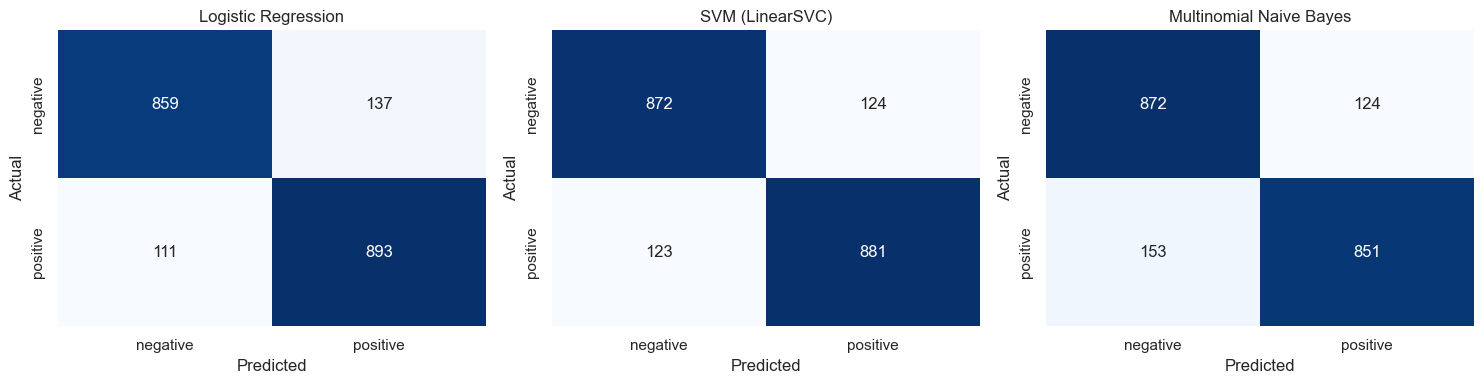

In [39]:
class_labels = sorted(y_test.unique())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## Section 9: Prediction on New Text

`predict_sentiment()` applies the **same preprocessing** and the **fitted TF-IDF vectorizer**, then asks the best model (highest test F1-score) for the class.

In [40]:
best_model_name = results_df["F1-score"].idxmax()
best_model = models[best_model_name]
print("Model used for prediction:", best_model_name)

def predict_sentiment(text):
    cleaned = preprocess_text(text)                 # same preprocessing as training
    features = tfidf.transform([cleaned])           # fitted vectorizer (no re-fitting)
    return best_model.predict(features)[0]

new_texts = [
    "This movie was absolutely wonderful, the acting was brilliant and I loved every minute!",
    "What a waste of time. The plot was boring and the acting was terrible.",
    "<p>Great story, fantastic soundtrack and a superb cast.</p>",
    "I did not enjoy this film at all. More details at http://example.com/review",
    "Not a bad film, I would happily watch it again.",
]

prediction_table = pd.DataFrame({
    "Original text": new_texts,
    "Predicted class": [predict_sentiment(t) for t in new_texts],
})
with pd.option_context("display.max_colwidth", None):
    display(prediction_table)

Model used for prediction: SVM (LinearSVC)


,Original text,Predicted class
0,"This movie was absolutely wonderful, the acting was brilliant and I loved every minute!",positive
1,What a waste of time. The plot was boring and the acting was terrible.,negative
2,"<p>Great story, fantastic soundtrack and a superb cast.</p>",positive
3,I did not enjoy this film at all. More details at http://example.com/review,positive
4,"Not a bad film, I would happily watch it again.",negative


**Note on these predictions.** The predictions are real outputs of the trained model. Simple bag-of-words / TF-IDF models only see word and bigram counts, so short or negation-heavy sentences (for example *"did not enjoy ... at all"* or *"not a bad film"*) can be classified wrongly, because the model cannot fully understand context. Keeping negations in the preprocessing helps, but does not remove this limitation.

### Save run summary
This cell writes the real numbers and examples from this run to `outputs/results/` (they are used to build the presentation, so the slides always match the notebook).

In [41]:
# --- excerpt of the sample review (around the first <br />) used on the slides
i = sample_text.find("<br />")
start = max(0, i - 70)
end = sample_text.find(".", i + 6) + 1          # end of the sentence after the tag
raw_excerpt = sample_text[start:end]
if start > 0:                                    # begin on a whole word
    raw_excerpt = raw_excerpt[raw_excerpt.find(" ") + 1:]
ex1 = to_lowercase(raw_excerpt)
ex2 = remove_html(ex1)
ex3 = remove_urls(ex2)
ex4 = re.sub(r"[^a-z\s]", " ", expand_negations(ex3))
ex5 = normalize_whitespace(ex4)
ex_tokens = tokenize(ex5)
ex_nostop = remove_stopwords(ex_tokens)

# --- words whose stem differs from their lemma (most frequent in the corpus)
word_freq = pd.Series([t for toks in df_work["tokens_no_stop"] for t in toks]).value_counts()
stem_vs_lemma = [{"word": w, "stem": _stem_word(w), "lemma": _lemmatize_word(w), "count": int(c)}
                 for w, c in word_freq.items() if _stem_word(w) != _lemmatize_word(w)][:6]

summary = {
    "dataset": {
        "name": "IMDB Movie Reviews (50K)",
        "source": DATA_URL,
        "file": DATA_PATH,
        "text_column": TEXT_COL,
        "label_column": LABEL_COL,
        "original_rows": int(len(df)),
        "original_class_counts": {k: int(v) for k, v in df[LABEL_COL].value_counts().items()},
        "duplicates": n_duplicates,
        "rows_after_dedup": int(n_after_dedup),
        "working_rows": int(len(df_work)),
        "working_class_counts": {k: int(v) for k, v in df_work[LABEL_COL].value_counts().items()},
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "reviews_with_html_pct": round(float(df[TEXT_COL].str.contains("<br />").mean() * 100), 1),
        "median_words": float(word_counts.median()),
    },
    "preprocessing_example": {
        "excerpt_original": raw_excerpt,
        "excerpt_lowercase": ex1,
        "excerpt_no_html": normalize_whitespace(ex2),
        "excerpt_no_url": normalize_whitespace(ex3),
        "excerpt_no_special": normalize_whitespace(re.sub(r"[^a-z\s]", " ", expand_negations(ex3))),
        "excerpt_whitespace": ex5,
        "excerpt_tokens": ex_tokens,
        "excerpt_no_stopwords": ex_nostop,
        "excerpt_stems": stem_tokens(ex_nostop),
        "excerpt_lemmas": lemmatize_tokens(ex_nostop),
        "stem_vs_lemma_words": stem_vs_lemma,
        "stopword_count": len(stopwords.words("english")),
        "negations_kept": sorted(negation_words),
    },
    "stage_statistics": stage_stats.to_dict(orient="records"),
    "features": {
        "bow_vocabulary": int(len(bow_vectorizer.vocabulary_)),
        "tfidf_features": int(X_train_tfidf.shape[1]),
        "tfidf_ngram_range": [1, 2],
        "tiny_bow_docs": tiny_docs,
        "tiny_bow_table": tiny_bow.to_dict(orient="split"),
        "top_bigrams": {k: int(v) for k, v in bigram_counts.head(5).items()},
        "negation_bigrams": {k: int(v) for k, v in neg_bigrams.head(5).items()},
    },
    "results": results_df.round(4).reset_index().to_dict(orient="records"),
    "best_model": best_model_name,
}
with open(os.path.join(RES_DIR, "run_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Saved:", os.path.join(RES_DIR, "run_summary.json"))

Saved: outputs\results\run_summary.json


---
## Section 10: Conclusion

- **Dataset:** IMDB movie reviews (`review` text, `sentiment` label); duplicates removed and a stratified working sample used, split 80:20 (stratified, `random_state=42`).
- **Preprocessing performed:** lowercasing, HTML removal, URL removal, special-character/punctuation removal (with negation handling), whitespace normalization, tokenization, stopword removal (negations kept), Porter stemming, WordNet lemmatization, and joining tokens into the final cleaned text.
- **Feature extraction:** Bag of Words (CountVectorizer), TF-IDF (TfidfVectorizer) and unigram + bigram n-grams, with vectorizers fitted on training data only.
- **Models implemented:** Logistic Regression, Support Vector Machine (LinearSVC) and Multinomial Naive Bayes, evaluated with accuracy, precision, recall, F1-score and confusion matrices.

In [42]:
# Final result summary from this run
print("Best model on the test set:", best_model_name)
display(results_df.round(4))

Best model on the test set: SVM (LinearSVC)


,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8760,0.8763,0.8759,0.8760
SVM (LinearSVC),0.8765,0.8765,0.8765,0.8765
Multinomial Naive Bayes,0.8615,0.8618,0.8616,0.8615
